# Практична робота №7
## Візуалізація: Figure і Axes, гістограма, boxplot, діаграма розсіювання

**Виконав:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Базові продажі:** 45 шт./день  
**Базова середньомісячна температура:** 2 °C

**Мета:** згенерувати синтетичні дані про продажі напоїв протягом 30 днів і побудувати коректні візуалізації в об'єктному інтерфейсі Matplotlib; продемонструвати наслідки спотворення графіка.

**Примітка:** усі дані є навчальними й відтворюваними завдяки `np.random.seed(5)`. Усього в роботі шість графіків: дві окремі гістограми, boxplot, scatterplot і пара для порівняння «коректний / спотворений».

## Підготовка середовища

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.dpi": 110,
    "axes.grid": False,
})

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib готовий до побудови графіків.")

NumPy: 2.3.5
pandas: 2.2.3
Matplotlib готовий до побудови графіків.


## Завдання 1. Побудова власного набору з 30 днів

`день` набуває значень від 1 до 30; `вихідний` позначає умовні суботу та неділю кожного семиденного циклу (6-й і 7-й дні). Температура коливається в межах **2 ± 3 °C**. Щоденні продажі мають випадкову складову, помірну позитивну залежність від температури та **надбавку 20% від базових 45 продажів (9 шт.)** у вихідні.

Використовується **номер варіанта 5** для генератора випадкових чисел.

In [2]:
np.random.seed(5)

n = 30
base_sales = 45
base_temp = 2

days = np.arange(1, n + 1)
weekend = (days - 1) % 7 >= 5

temperature = np.round(
    base_temp + np.clip(np.random.normal(0, 1.45, size=n), -3, 3),
    1,
)

sales = np.rint(
    base_sales
    + 1.5 * (temperature - base_temp)
    + np.random.normal(0, 2.2, size=n)
    + weekend * (base_sales * 0.20)
).astype(int)

kiosk = pd.DataFrame({
    "день": days,
    "вихідний": weekend,
    "температура": temperature,
    "продажі": sales,
})

assert kiosk.shape == (30, 4)
assert kiosk["день"].tolist() == list(range(1, 31))
assert kiosk["вихідний"].dtype == bool
assert kiosk["температура"].between(-1, 5).all()
assert (kiosk["продажі"] > 0).all()

print("Форма DataFrame:", kiosk.shape)
print("Кількість вихідних:", kiosk["вихідний"].sum())
print("Діапазон температур:", kiosk["температура"].min(), "...", kiosk["температура"].max(), "°C")
print("Типи стовпців:\n", kiosk.dtypes)
display(kiosk)

Форма DataFrame: (30, 4)
Кількість вихідних: 8
Діапазон температур: -0.4 ... 5.0 °C
Типи стовпців:
 день             int64
вихідний          bool
температура    float64
продажі          int64
dtype: object


,день,вихідний,температура,продажі
0,1,False,2.6,48
1,2,False,1.5,43
2,3,False,5.0,49
3,4,False,1.6,44
4,5,False,2.2,45
5,6,True,4.3,58
6,7,True,0.7,52
7,8,False,1.1,47
8,9,False,2.3,45
9,10,False,1.5,48


## Завдання 2. Гістограми продажів з різними `bins`

Кожна гістограма показує, скільки днів потрапляє до інтервалу денних продажів. Побудова — через `Figure` і `Axes`, а не через глобальний `plt.hist()`.

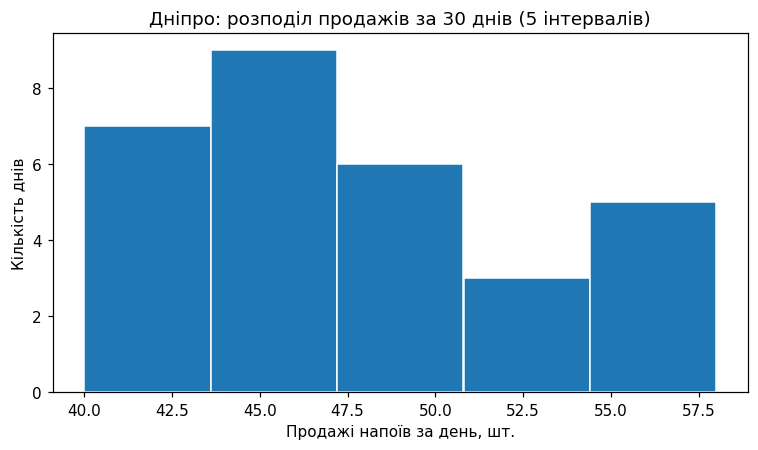

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(kiosk["продажі"], bins=5, edgecolor="white", linewidth=1)
ax.set_xlabel("Продажі напоїв за день, шт.")
ax.set_ylabel("Кількість днів")
ax.set_title("Дніпро: розподіл продажів за 30 днів (5 інтервалів)")
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

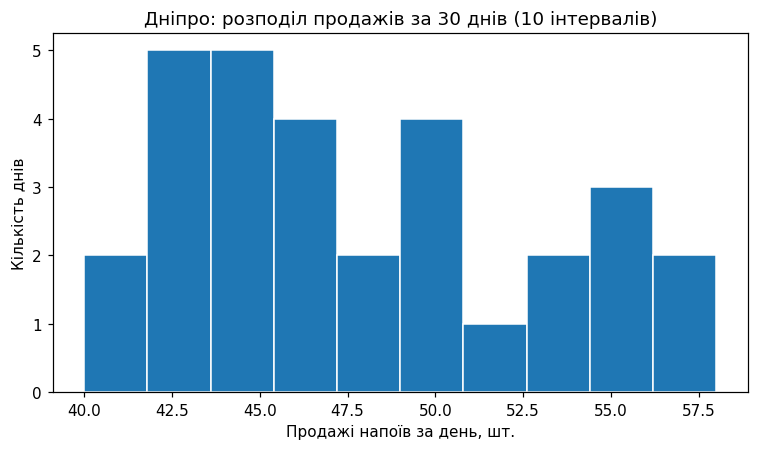

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(kiosk["продажі"], bins=10, edgecolor="white", linewidth=1)
ax.set_xlabel("Продажі напоїв за день, шт.")
ax.set_ylabel("Кількість днів")
ax.set_title("Дніпро: розподіл продажів за 30 днів (10 інтервалів)")
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

**Порівняння.** Для 30 спостережень гістограма з **5 інтервалами** зрозуміліша: вона групує близькі значення та показує загальний розподіл без надмірних коливань частот. За **10 інтервалів** у кожному опиняється мало днів, тому окремі високі/низькі стовпці легше помилково сприйняти як важливу структуру. Обидві версії мають однакові дані, відрізняється лише деталізація.

## Завдання 3. Boxplot: будні та вихідні

Порівнюємо дві незалежні підмножини: денні продажі в будні та у вихідні. На boxplot лінія всередині ящика — медіана; межі ящика — квартилі Q1 і Q3.

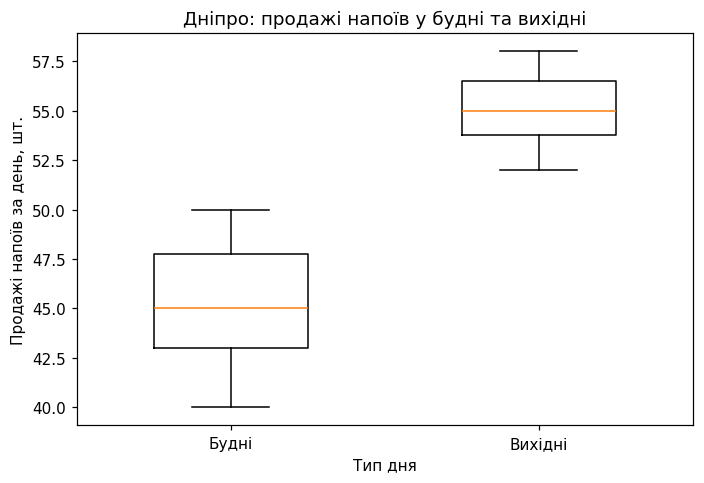

,Тип дня,Кількість днів,"Медіана, шт.","Середнє, шт.","IQR, шт.","std, шт."
0,Будні,22,45.0,45.27,4.75,2.91
1,Вихідні,8,55.0,55.12,2.75,2.17


In [5]:
weekdays_sales = kiosk.loc[~kiosk["вихідний"], "продажі"]
weekends_sales = kiosk.loc[kiosk["вихідний"], "продажі"]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.boxplot(
    [weekdays_sales, weekends_sales],
    tick_labels=["Будні", "Вихідні"],
    widths=0.5,
)
ax.set_xlabel("Тип дня")
ax.set_ylabel("Продажі напоїв за день, шт.")
ax.set_title("Дніпро: продажі напоїв у будні та вихідні")
fig.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Тип дня": ["Будні", "Вихідні"],
    "Кількість днів": [len(weekdays_sales), len(weekends_sales)],
    "Медіана, шт.": [weekdays_sales.median(), weekends_sales.median()],
    "Середнє, шт.": [weekdays_sales.mean(), weekends_sales.mean()],
    "IQR, шт.": [
        weekdays_sales.quantile(.75) - weekdays_sales.quantile(.25),
        weekends_sales.quantile(.75) - weekends_sales.quantile(.25),
    ],
    "std, шт.": [weekdays_sales.std(), weekends_sales.std()],
})
display(comparison.round(2))

**Інтерпретація.** Медіана у вихідні становить **55 шт.**, у будні — **45 шт.**; тобто у вихідні вона на **10 шт. вища**. Це відповідає моделі з додатковими 9 продажами у вихідні. У цьому конкретному згенерованому наборі IQR **менший у вихідні** (2,75 проти 4,75 шт.), отже розкид центральних 50% спостережень дещо вужчий. Це особливість випадкової вибірки, а не загальне правило для вихідних.

## Завдання 4. Діаграма розсіювання: температура та продажі

Вісь X — температура повітря (°C); вісь Y — кількість проданих напоїв (шт./день). Для числових величин scatterplot доречний, бо показує пари спостережень без штучного з'єднання точок.

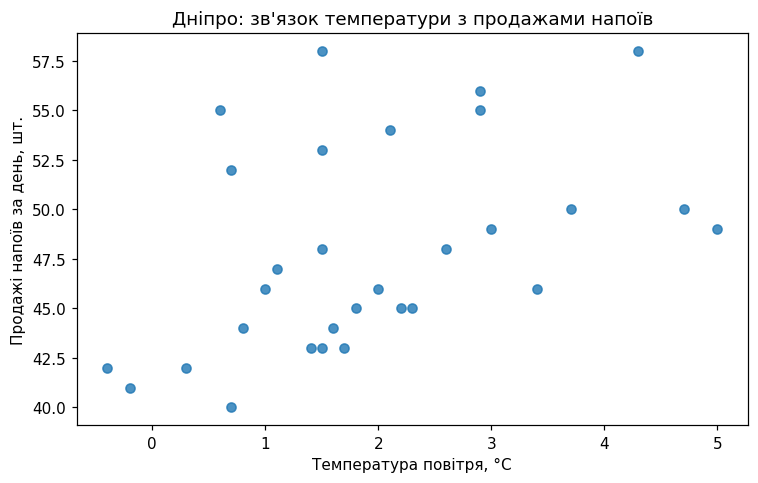

Коефіцієнт кореляції Пірсона r = 0.443


In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(kiosk["температура"], kiosk["продажі"], alpha=0.8)
ax.set_xlabel("Температура повітря, °C")
ax.set_ylabel("Продажі напоїв за день, шт.")
ax.set_title("Дніпро: зв'язок температури з продажами напоїв")
fig.tight_layout()
plt.show()

correlation = kiosk["температура"].corr(kiosk["продажі"])
print(f"Коефіцієнт кореляції Пірсона r = {correlation:.3f}")

**Інтерпретація.** Видно **помірну позитивну залежність**: за вищої температури продажі загалом дещо більші (`r ≈ 0,443`). Для кіоску гарячих і холодних напоїв це правдоподібно, оскільки потепління може стимулювати купівлю холодних напоїв. Розкид залишається значним через вихідні та випадкові коливання. Кореляція не доводить причинності; напрям зв'язку частково закладений у формулу генерації.

## Завдання 5. Навмисно спотворена гістограма

Побудуємо **поруч** дві гістограми з тими самими даними та однаковими інтервалами. Зліва — коректна версія, справа — навмисно спотворена: без назв осей, одиниць вимірювання та числових підписів поділок. Висоти стовпців і масштаб даних **не змінені**.

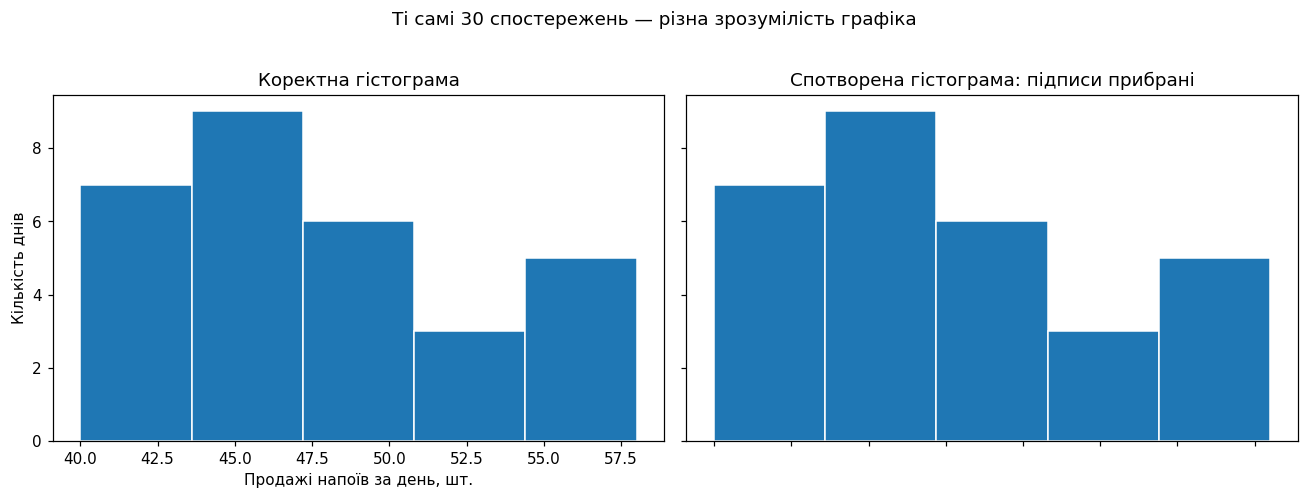

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True, sharey=True)

axes[0].hist(kiosk["продажі"], bins=5, edgecolor="white", linewidth=1)
axes[0].set_title("Коректна гістограма")
axes[0].set_xlabel("Продажі напоїв за день, шт.")
axes[0].set_ylabel("Кількість днів")
axes[0].set_ylim(bottom=0)

axes[1].hist(kiosk["продажі"], bins=5, edgecolor="white", linewidth=1)
axes[1].set_title("Спотворена гістограма: підписи прибрані")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis="both", which="both", labelbottom=False, labelleft=False)

fig.suptitle("Ті самі 30 спостережень — різна зрозумілість графіка", y=1.02)
fig.tight_layout()
plt.show()

**Яке спотворення застосовано?** Це **відсутність контексту та підписів**, розглянута серед типових порушень коректної візуалізації. Праворуч не зрозуміло, що по X відкладено кількість проданих напоїв у штуках, а по Y — кількість днів. Без числових позначок складно оцінити діапазон і частоти. Глядачеві легше помилково інтерпретувати дані, хоча самі значення не змінено. Лівий графік коректний, бо має назви обох осей, одиниці, заголовок і нульову основу для частот.

**Важливо:** навмисне спотворення виконане **тільки** у цьому порівнянні, як того вимагає завдання; основні графіки вище залишаються повністю підписаними.

## Контрольні питання

**1. Чому обрізана вісь Y на стовпчиковій діаграмі перебільшує різницю між категоріями?**

Стовпчикова діаграма передає значення **висотою стовпчиків**. Наприклад, для значень 90 і 100 за нульової основи різниця в довжині невелика (близько 11% від 90). Якщо почати вісь Y з 85, видимі висоти стануть 5 і 15 одиниць — другий стовпчик здаватиметься втричі вищим. Підписані значення правильні, але візуальне порівняння вводить в оману.

**2. Коли лінійний графік буде методологічною помилкою для категоріальних даних?**

Якщо показати кількість продажів у трьох незалежних містах («Дніпро», «Львів», «Одеса») та **з'єднати точки лінією**, виникне хибне враження безперервного переходу між містами. Назва міста має **номінальну шкалу**: між категоріями немає числової відстані або природного порядку. Краще використати стовпчикову чи точкову діаграму за категоріями. Лінія доречна, наприклад, у часовому ряді, де є осмислений порядок точок.

**3. Чому підписи осей, одиниці та заголовок — частина твердження графіка, а не оздоблення?**

Без них не можна однозначно сказати, які величини порівнюються, які одиниці використовуються та який період/об'єкт досліджується. Наприклад, числа 45 і 55 можуть бути штуками напоїв, гривнями або відсотками. Назви осей і заголовок роблять інтерпретацію перевірюваною, а не довільною.

**4. Що таке chartjunk і чому він шкодить?**

**Chartjunk** — зайві декоративні елементи, що не допомагають прочитати дані: 3D-ефекти, тіні, надмірні градієнти, фонові зображення та прикраси. Наприклад, перспектива 3D-стовпчиків може візуально змінити їхню висоту та утруднити порівняння. Краще використовувати прості двовимірні графіки з чіткими підписами.

## Висновок

Для **Дніпра (варіант №5)** створено DataFrame з 30 навчальних днів продажів напоїв. За допомогою `fig, ax = plt.subplots()` і методів `Axes` побудовано **шість** графіків (2 гістограми, boxplot, scatterplot і 2 порівняльні гістограми). Встановлено, що у вихідні продажі вищі, а між температурою та продажами є помірний позитивний зв'язок. Порівняння правильної гістограми зі спотвореною показало, чому підписи та одиниці вимірювання є обов'язковими. Усі відповіді на контрольні питання наведено вище.